In [ ]:
!pip install ultralytics -q

In [ ]:
from google.colab import drive
drive.mount('/drive')

In [ ]:
from ultralytics import YOLO
model = YOLO("___your_model_path____") #created an obj

In [ ]:
help(model.predict)

In [ ]:
result = model("_____image_path_______", conf=0.75,  iou=0.2) #return a complex obj

boxes = result[0].boxes
#boxes itself is another complex object with different attributes
print(boxes.xyxy)
print(boxes.conf)
print(boxes.cls)

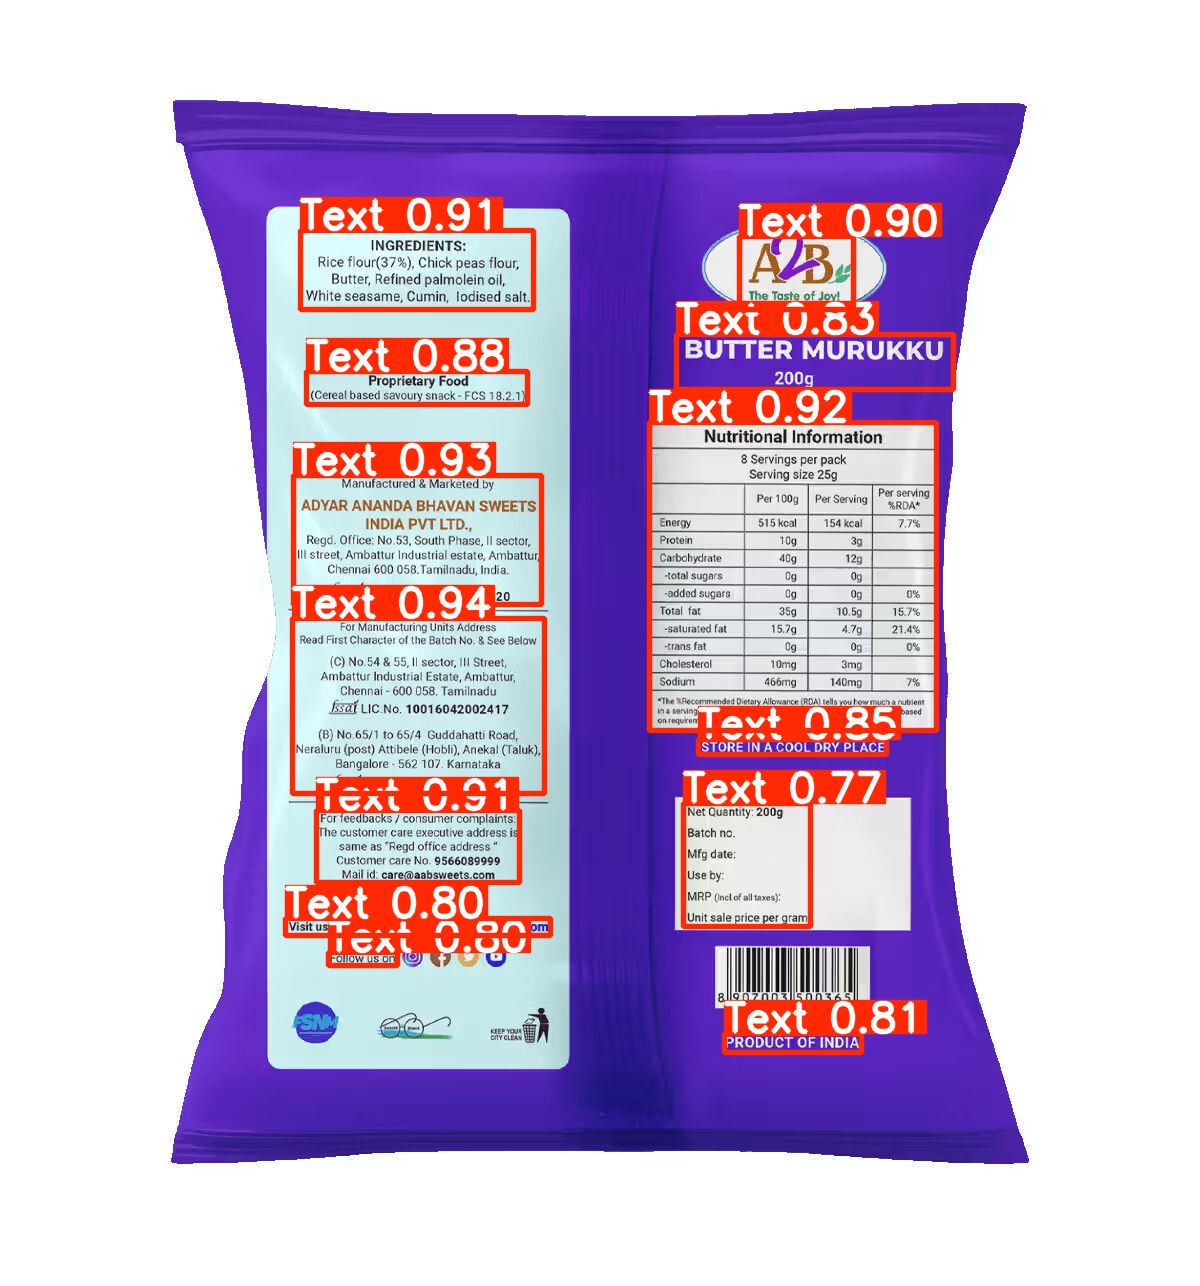

In [ ]:
#knowing what result is ->
# print(type(result))
# print(len(result))
# print(len(result[0]))
# print(type(result[0]))
# print(result[0].boxes)

from PIL import Image
img = result[0].plot()
display(Image.fromarray(img))


In [ ]:
!pip uninstall -y paddleocr paddlepaddle paddlex

!pip install paddlepaddle==3.0.0
!pip install paddleocr==2.10.0

In [ ]:
from paddleocr import PaddleOCR
#can use lang = 'multilingual'
ocr = PaddleOCR(lang='en', use_angle_cls=True, show_log=False)

In [ ]:
boxes_cordinate = boxes.xyxy.cpu().numpy()
print(type(boxes_cordinate))
print(boxes_cordinate.shape)
print(boxes_cordinate[0])


<class 'numpy.ndarray'>
(13, 4)
[     292.33      618.35       544.5      793.82]


In [ ]:
import cv2
import paddle
import paddleocr

boxes_cordinate = boxes.xyxy.cpu().numpy()
output=[]

print("paddle:", paddle.__version__)
print("paddleocr:", paddleocr.__version__)

img = cv2.imread("____image_path_____")

for i, box in enumerate(boxes_cordinate):

    x1, y1, x2, y2 = map(int, box)

    crop = img[y1:y2, x1:x2]
    ocr_result = ocr.ocr(crop)
    # output.append(ocr_result)

    text = ""

    if ocr_result and ocr_result[0]:
        text = " ".join(
            line[1][0]
            for line in ocr_result[0]
        )

    output.append({
        "box_id": i,
        "bbox" :[x1, y1, x2, y2],
        "text": text
    })


paddle: 3.0.0
paddleocr: 2.10.0


In [ ]:
from pprint import pprint
print(output)
pprint(output)

[{'box_id': 0, 'bbox': [292, 618, 544, 793], 'text': 'For Manufacturing Units Address Read First Character of the Batch No.& See Below CNo.54 &55sector Street Ambattur Industrial Estate,Ambattur Chennai-600 058.Tamilnadu saLIC.No.10016042002417 BNo.65/1 to 65/4 Guddahatti Road Neraluru post Attibele Hobli)Anekal Taluk Bangalore-562107.Karnataka saLIC No.11220302000226'}, {'box_id': 1, 'bbox': [293, 475, 541, 604], 'text': 'Manufactured & Marketed by ADYAR ANANDA BHAVAN SWEETS INDIA PVT LTD. Regd.OfficeNo.53South Phase,l sector II street,Ambattur Industrial estate, Ambattur, Chennai 600058.Tamilnadu,India. fssaLic No.10016042002420'}, {'box_id': 2, 'bbox': [649, 422, 936, 730], 'text': 'Nutritional Information 8 Servings per pack Serving size 25g Per 100g Per Serving Per serving %RDA* Energy 515 kcal 154kcal 7.7% Protein 10g 3g Carbohydrate 40g 12g -total sugars 0g 0g peuans pappe- 0g 0g 0% Total fat 35g 10.5g 15.7% -saturated fat 15.7g 4.7g 21.4% -trans fat 0g 0g 0% Cholesteral 10mg 3m

In [ ]:
!pip install groq

In [ ]:
from groq import Groq
import json

client = Groq(api_key="______your_groq_api_key_______")

prompt = f"""
You are analyzing OCR regions from a food package.

Find the OCR region that contains the ingredients list.

Return json format only that contains the box number, bbox and the postprocessed corrected text

OCR Regions:
{json.dumps(output, indent=2)}
"""

response = client.chat.completions.create(
    model="llama-3.3-70b-versatile",
    messages=[
        {
            "role": "user",
            "content": prompt
        }
    ],
    temperature=0
)

print(response.choices[0].message.content)

```json
{
  "box_id": 4,
  "bbox": [300, 230, 533, 309],
  "text": "INGREDIENTS: Rice flour (37%), Chick peas flour, Butter, Refined palmolein oil, White seasame, Cumin, lodised salt."
}
```
